# 6. Interface, container, deployment, monitoring

Three steps remain from the talk:

3. **Put a simple interface in front of it**
4. **Containerise and deploy it**
5. **Monitor it**, because deployment is the beginning, not the end

Each one is shaped by Burundi's reality: about 11% internet use, LTE on under 16% of the territory, and most subscribers on GSM.

In [1]:
import json, os, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ["IMBUTO_ROOT"] = str(ROOT)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
GREEN, GREY, BROWN = "#1f6e3f", "#9aa89f", "#8c510a"

In [2]:
import gzip, tempfile, time
from fastapi.testclient import TestClient
from imbuto.api.main import create_app
from imbuto.core.service import Imbuto
from imbuto.settings import Settings
core = Imbuto(Settings(db_path=Path(tempfile.mkdtemp()) / "demo.sqlite"))
client = TestClient(create_app(core))

/Users/desmondonnam/Desktop/projects/AI/Imbuto_AI/.venv/lib/python3.12/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


## The interface is not always a screen

For most Burundian farmers, the "interface" is a keypad. So the same core serves every channel:

| Channel | Needs | Serves |
| --- | --- | --- |
| USSD | Any phone, no data | Menus |
| SMS | Any phone, no data | Commands and alerts |
| Voice | Any phone, no reading | Keypad menu with recorded Kirundi |
| Web app | Smartphone | Photos, questions, offline pages |
| Dashboard | Browser | Ministries, co-ops, NGOs |

Here is a real USSD session, using the common `CON` (continue) and `END` format.

In [3]:
def press(text): return client.post("/gateway/ussd", data={"sessionId": "nb1", "phoneNumber": "+25769000001", "text": text}).text
path = ""
for step in ["", "3", "1", "3", "1", "1", "1"]:
    path = (path + "*" + step).strip("*") if step else path
    print(f"--- pressed {step or 'dial'}\n{press(path)}\n")

--- pressed dial
CON Hitamwo / Choisir / Choose
1 Ikirundi
2 Francais
3 English

--- pressed 3
CON We keep your number, area and questions to send alerts and improve this service. SMS STOP deletes them.
1 Agree
2 No thanks

--- pressed 1
CON Your province?
1 Buhumuza
2 Bujumbura
3 Burunga
4 Butanyerera
5 Gitega

--- pressed 3
CON Your district?
1 Bururi
2 Makamba
3 Rumonge
4 Rutana

--- pressed 1
CON Your commune?
1 Bururi
2 Matana
3 Mugamba
4 Rutovu
5 Songa
6 Vyanda
9 More

--- pressed 1
CON Imbuto AI
1 Rain
2 Market prices
3 Advice
4 Report a problem
5 Talk to a person
6 Change area

--- pressed 1
END Bururi: 22 mm so far this season, 47% of normal (very dry). Data to 2026-09.



SMS replies must fit **one 160-character GSM-7 segment**. One accented character can switch a whole message to a more expensive encoding, cutting the limit to 70 characters. So we strip accents on this channel.

In [4]:
def sms(text): return client.post("/gateway/sms", data={"from": "+25769000002", "text": text}).text
for message in ["KOMINE Bugarama", "IMVURA", "IGICIRO IBIGORI", "INAMA beans orange rust"]:
    reply = sms(message); print(f"{message:26} -> [{len(reply)} chars] {reply}")

KOMINE Bugarama            -> [24 chars] Agace kabitswe: Bugarama
IMVURA                     -> [83 chars] Bugarama: 38 mm muri iki gihe, 68% y'ibisanzwe (bisanzwe). Amakuru gushika 2026-09.
IGICIRO IBIGORI            -> [42 chars] Ibigori: 1 708 BIF/kg i Rumonge (2026-08).
INAMA beans orange rust    -> [85 chars] Indwara ya rouille iba utudomo tw'umuhondo. Kura amababi yafashwe, ubaze umujejetafu.


Voice uses the same menu, returned as gateway XML. Pressing keys needs **no speech recognition**, so voice can launch as soon as a native speaker records the prompts. Kirundi speech models can come later.

> **Provider warning.** Africa's Talking's published list does not include Burundi. Channels here are gateway-neutral, and real access means agreeing terms with an in-country aggregator or operator, with short codes approved by the regulator, ARCT.

## The 2G budget, as tests

A budget nobody checks is a wish. These limits are enforced by `tests/test_performance_budget.py`, so a heavy change fails the build.

In [5]:
rows = []
for path in ["/", "/ask", "/prices", "/photo", "/area"]:
    body = client.get(path).content; zipped = len(gzip.compress(body, 9))
    rows.append({"page": path, "raw KB": round(len(body) / 1000, 1), "gzipped KB": round(zipped / 1000, 1), "seconds at 40 kbps": round(zipped * 8 / 40_000, 2)})
pd.DataFrame(rows)

,page,raw KB,gzipped KB,seconds at 40 kbps
0,/,1.9,0.9,0.19
1,/ask,1.9,0.9,0.19
2,/prices,2.0,0.9,0.19
3,/photo,2.1,1.1,0.21
4,/area,7.1,2.0,0.40


Network round trips and packet loss add to these times, so they are lower bounds. Pages work with JavaScript off. With it on, a service worker keeps pages available offline, and photos taken without signal wait in the browser until it returns.

## Step 4: containerise

`deploy/Dockerfile` uses two stages, so build tools stay out of the final image, and runs as a non-root user.

```bash
docker compose -f deploy/docker-compose.yml up --build
curl localhost:8000/readyz
```

Why bother? The same image runs on a laptop, a cloud VM, or a server in Bujumbura if data rules require it. That last option is how we keep **data sovereignty** open.

**Deployment choices for Burundi:**

- One small VM is enough. Rain answers are precomputed, so a USSD reply needs no model call.
- Host near users where possible. Every round trip counts on 2G.
- Power and links fail. Use `restart: unless-stopped`, health checks, and back up the SQLite file.
- Bundle size counts when deploying over a slow link, so the image has no training stack.

**How fast is an answer?** USSD sessions time out quickly, so we measure rather than assume.

In [6]:
samples = []
for i in range(100):
    start = time.perf_counter()
    client.post("/gateway/ussd", data={"sessionId": f"lat{i}", "phoneNumber": "+25769000003", "text": ""})
    samples.append((time.perf_counter() - start) * 1000)
print(f"USSD handler time on this laptop: median {np.median(samples):.1f} ms, p95 {np.percentile(samples, 95):.1f} ms")

USSD handler time on this laptop: median 9.2 ms, p95 11.1 ms


## Step 5: monitor it

Normal services fail loudly. Models fail **quietly**: same 200 OK, worse answers. So we watch four layers:

| Layer | Question | Signal |
| --- | --- | --- |
| Service | Is it up and fast? | `/readyz`, latency, Prometheus metrics |
| Data | Do inputs still look like training? | Drift (PSI) |
| Model | Is it still right? | Farmer feedback, unsure rate |
| Product | Is it helping? | Questions sent to people, knowledge gaps |

We now simulate this. Normal photos go first, then the same photos darkened and blurred, like a dusty lens at dusk. **This is simulated traffic, not field data.**

In [7]:
import io
from PIL import Image, ImageEnhance, ImageFilter
from imbuto.ml.crop_health import shrink_for_upload
from imbuto.monitoring.metrics import psi
table = pd.read_parquet(ROOT / "data/bronze/beans/test.parquet")
photos = [Image.open(io.BytesIO(r["bytes"])) for r in table.image]
def degrade(i): return ImageEnhance.Brightness(i.convert("RGB")).enhance(.45).filter(ImageFilter.GaussianBlur(4))
reference = core.crop_model.card["metrics"]["reference_confidence"]
normal = [core.diagnose(shrink_for_upload(p), "en", "demo").diagnosis for p in photos[::2]]
drifted = [core.diagnose(shrink_for_upload(degrade(p)), "en", "demo").diagnosis for p in photos[1::2]]
def report(ds):
    conf = [d.confidence for d in ds if d.outcome != "not_a_leaf"]
    return {"photos": len(ds), "unsure or not a leaf": f"{np.mean([d.outcome != 'confident' for d in ds]):.0%}", "PSI": round(psi(reference, conf), 2) if len(conf) >= 5 else None}
pd.DataFrame({"normal": report(normal), "drifted": report(drifted)}).T

,photos,unsure or not a leaf,PSI
normal,64,17%,0.07
drifted,64,47%,0.37


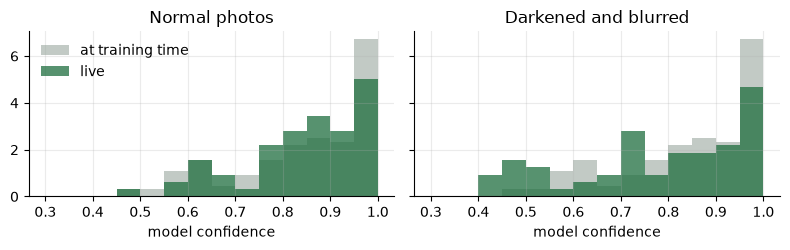

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(8, 2.6), sharex=True, sharey=True)
bins = np.linspace(.3, 1, 15)
for ax, ds, title in zip(axes, (normal, drifted), ("Normal photos", "Darkened and blurred")):
    ax.hist(reference, bins=bins, density=True, color=GREY, alpha=.6, label="at training time")
    ax.hist([d.confidence for d in ds], bins=bins, density=True, color=GREEN, alpha=.75, label="live"); ax.set(title=title, xlabel="model confidence")
axes[0].legend(frameon=False); plt.tight_layout(); plt.show()

Read the two pieces of evidence together. The drifted batch gets flagged by the system's own checks: the model says "unsure" or "not a leaf" far more often. PSI on the photos accepted as leaves is a second, rougher signal, and it needs a decent sample size, so `/ops` shows it only from 30 predictions.

Note that with no labels in the field, this is often **all** we have. Farmer feedback is what eventually closes the gap.

## Closing the loop

Monitoring only matters if it leads to action.

| Signal | Action |
| --- | --- |
| Drift alert | Review photos, collect examples, retrain |
| Many "not a leaf" | Improve the photo guidance in Kirundi |
| Questions sent to people | Ask agronomists to add approved answers |
| Feedback disagrees | Add to the local test set |

Every retrain passes through the same gates as notebooks 3 and 4.

## What is simulated, and what is not

**Real:** rainfall, prices, crop images, trained models, every channel's logic, tests.
**Not yet real:** operator connections, Kirundi audio, field traffic, reviewed content. See `docs/REVIEW_NEEDED.md`.